# Experiment 1 – Social contagion: diaspora-pull sweep
Reads a BehaviorSpace *table* export (any run of the contagion sweep, every-10-ticks or final-only) and reproduces the dose-response, time-course and timing figures. Time axis uses the `ticks` column, not `[step]`.

In [35]:
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.style.use('ggplot')

FILE = 'Diaspora_sweep_v2.csv'        # <- path to the BehaviorSpace table export
OUTCOME = 'unique-migrants'           # first-time migrants (excludes re-entry churn)
NET, DIA, SEED = 'network-strength', 'diaspora-signal', 'global-seed'

In [36]:
def load_table(path):
    """BehaviorSpace table export: 6 metadata lines, then header."""
    d = pd.read_csv(path, skiprows=6)
    d.columns = [c.strip() for c in d.columns]
    # BehaviorSpace repeats a column when a metric is listed twice; pandas renames the copy 'name.1'
    dup = [c for c in d.columns if c.endswith('.1') and c[:-2] in d.columns]
    d = d.drop(columns=dup)
    return d

d = load_table(FILE)
runs = d['[run number]'].nunique()
rows_per_run = d.groupby('[run number]').size().unique()
print(f"{len(d):,} rows | {runs} runs | rows/run {rows_per_run} | ticks {d.ticks.min()}-{d.ticks.max()}")
print(d.groupby([NET, DIA]).size().unstack().rename_axis(index='network', columns='diaspora'))
assert d[SEED].nunique() * d[NET].nunique() * d[DIA].nunique() == runs, 'design is not fully crossed'
T_END = d.ticks.max()

180,300 rows | 300 runs | rows/run [601] | ticks 0-6000
diaspora   0.00   0.25   0.50   1.00   2.00
network                                    
0.0       18030  18030  18030  18030  18030
0.4       18030  18030  18030  18030  18030


In [37]:
d

,[run number],initial-ability-level,network-strength,num-turtles,show-links,initial-aspiration-level,max-links,global-seed,diaspora-signal,[step],...,share-high-ability,cumulative-net-boost,cumulative-peer-pressure,cumulative-diaspora-pull,cumulative-exits,count turtles with [color = cyan],count turtles with [color = green],count turtles with [color = yellow],count turtles with [color = red],count turtles with [color = orange]
0,5,All,0.0,200,False,All,2,1,2.00,0,...,0.51,0.0,0.00,0.000,0,28,23,30,68,51
1,7,All,0.0,200,False,All,2,2,0.25,0,...,0.42,0.0,0.00,0.000,0,19,20,33,83,45
2,6,All,0.0,200,False,All,2,2,0.00,0,...,0.42,0.0,0.00,0.000,0,19,20,33,83,45
3,10,All,0.0,200,False,All,2,2,2.00,0,...,0.42,0.0,0.00,0.000,0,19,20,33,83,45
4,4,All,0.0,200,False,All,2,1,1.00,0,...,0.51,0.0,0.00,0.000,0,28,23,30,68,51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180295,300,All,0.4,200,False,All,2,30,2.00,597,...,0.71,76.0,10.96,1556.996,59,5,78,3,55,59
180296,299,All,0.4,200,False,All,2,30,1.00,600,...,0.71,72.4,9.16,748.555,59,12,71,7,51,59
180297,300,All,0.4,200,False,All,2,30,2.00,598,...,0.71,76.0,10.96,1559.976,59,5,78,3,55,59
180298,300,All,0.4,200,False,All,2,30,2.00,599,...,0.71,76.0,10.96,1562.956,59,5,78,3,55,59


In [38]:
# Paired layout: one row per (net, dia, seed), one column per tick
P = d.pivot_table(index=[NET, DIA, SEED], columns='ticks', values=OUTCOME)
fin = P[T_END]
print("Mean first-time migrants at final tick")
print(fin.groupby([NET, DIA]).mean().unstack().round(2))

Mean first-time migrants at final tick
diaspora-signal    0.00   0.25   0.50   1.00   2.00
network-strength                                   
0.0               41.47  47.43  53.03  63.23  75.03
0.4               43.17  49.30  55.00  65.23  75.67


## 1. Dose-response at the final tick (paired by seed)

In [39]:
def paired(n, dv, t=T_END, base=0.0):
    a, b = P.loc[(n, dv), t], P.loc[(n, base), t]
    x = (a - b).values
    rng = np.random.default_rng(0)
    bs = [rng.choice(x, len(x)).mean() for _ in range(5000)]
    return dict(net=n, dia=dv, gain=x.mean(), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5),
                p_t=stats.ttest_rel(a, b).pvalue, p_w=stats.wilcoxon(a, b).pvalue)

tab = pd.DataFrame([paired(n, dv) for n in sorted(d[NET].unique()) for dv in sorted(d[DIA].unique()) if dv > 0])
tab.assign(p_t=tab.p_t.map('{:.1e}'.format), p_w=tab.p_w.map('{:.1e}'.format)).round(3)

,net,dia,gain,lo,hi,p_t,p_w
0,0.0,0.25,5.967,5.100,6.800,9.4e-14,2.4e-06
1,0.0,0.50,11.567,10.467,12.733,2.4e-18,1.6e-06
2,0.0,1.00,21.767,20.433,23.133,6.8e-24,1.7e-06
3,0.0,2.00,33.567,31.300,35.800,8.3e-23,1.7e-06
4,0.4,0.25,6.133,5.300,7.033,4.9e-14,1.6e-06
5,0.4,0.50,11.833,10.767,12.901,4.3e-19,1.7e-06
6,0.4,1.00,22.067,20.433,23.733,1.1e-21,1.7e-06
7,0.4,2.00,32.500,30.233,34.667,1.5e-22,1.7e-06


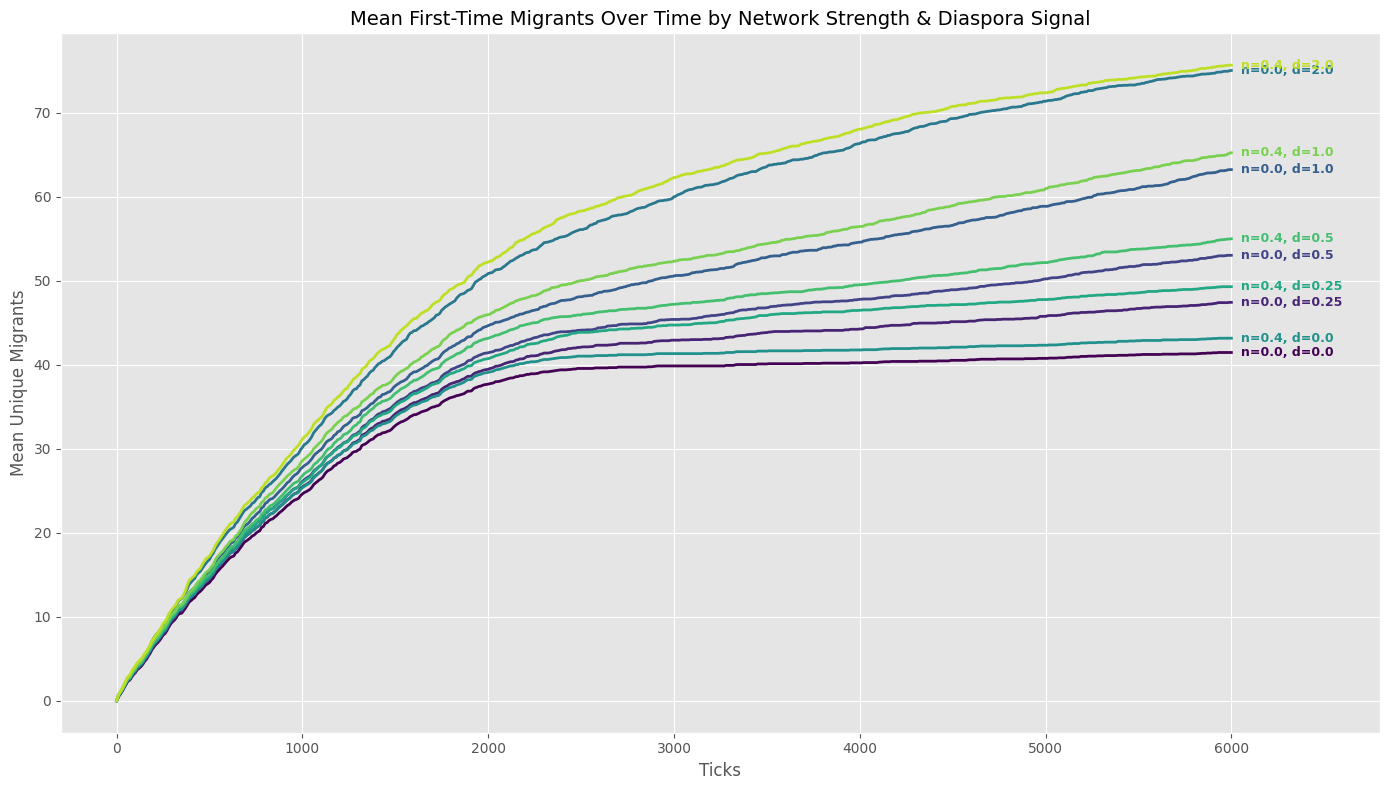

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the BehaviorSpace output CSV file
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Group by network-strength, diaspora-signal, and ticks, then calculate the mean of unique-migrants
grouped = df.groupby(['network-strength', 'diaspora-signal', 'ticks'])['unique-migrants'].mean().reset_index()

# 3. Plot the time-course lines with labels placed directly on the lines
plt.figure(figsize=(14, 8))
plt.style.use('ggplot')

unique_combinations = grouped.groupby(['network-strength', 'diaspora-signal']).size().reset_index()
num_colors = len(unique_combinations)
colors = plt.cm.viridis(np.linspace(0, 0.9, num_colors))

# We will label lines on the plot directly near the end points (x ≈ 6000)
for i, ((net, dia), sub_df) in enumerate(grouped.groupby(['network-strength', 'diaspora-signal'])):
    # Sort by ticks to ensure continuous line
    sub_sorted = sub_df.sort_values('ticks')
    line, = plt.plot(
        sub_sorted['ticks'],
        sub_sorted['unique-migrants'],
        color=colors[i],
        linewidth=2
    )

    # Get coordinates for the last data point to place the text label
    last_row = sub_sorted.iloc[-1]
    x_pos = last_row['ticks']
    y_pos = last_row['unique-migrants']

    # Offset slightly to the right to avoid overlapping the line
    plt.text(
        x_pos + 50,
        y_pos,
        f"n={net}, d={dia}",
        color=colors[i],
        fontsize=9,
        weight='bold',
        va='center'
    )

plt.title('Mean First-Time Migrants Over Time by Network Strength & Diaspora Signal', fontsize=14)
plt.xlabel('Ticks', fontsize=12)
plt.ylabel('Mean Unique Migrants', fontsize=12)
plt.xlim(right=6800)  # Extend x limit to make room for inline labels
plt.tight_layout()
plt.show()

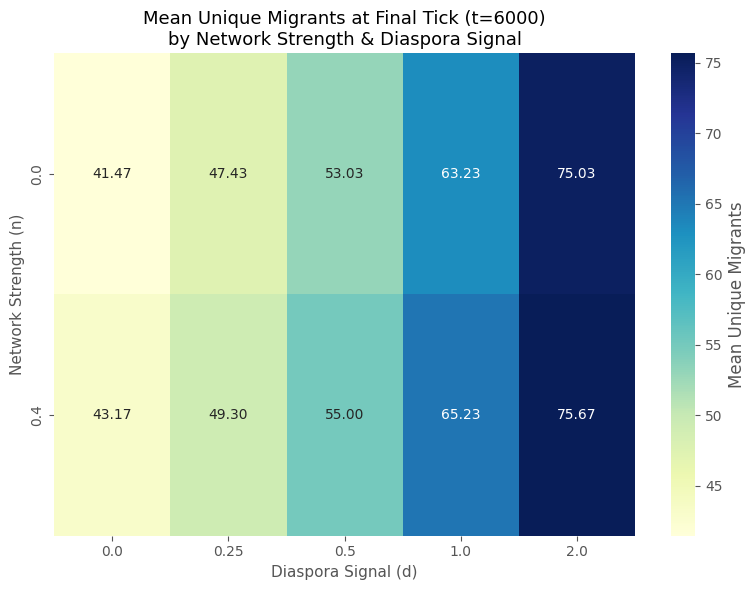

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Filter for the final timestep where differences are most pronounced
final_df = df[df['ticks'] == 6000]

# 3. Create a pivot table of mean unique-migrants
pivot_table = final_df.pivot_table(
    values='unique-migrants',
    index='network-strength',
    columns='diaspora-signal',
    aggfunc='mean'
)

# 4. Plot as a heatmap to show clear gradients
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Mean Unique Migrants'})
plt.title('Mean Unique Migrants at Final Tick (t=6000)\nby Network Strength & Diaspora Signal', fontsize=13)
plt.xlabel('Diaspora Signal (d)', fontsize=11)
plt.ylabel('Network Strength (n)', fontsize=11)
plt.tight_layout()
plt.show()

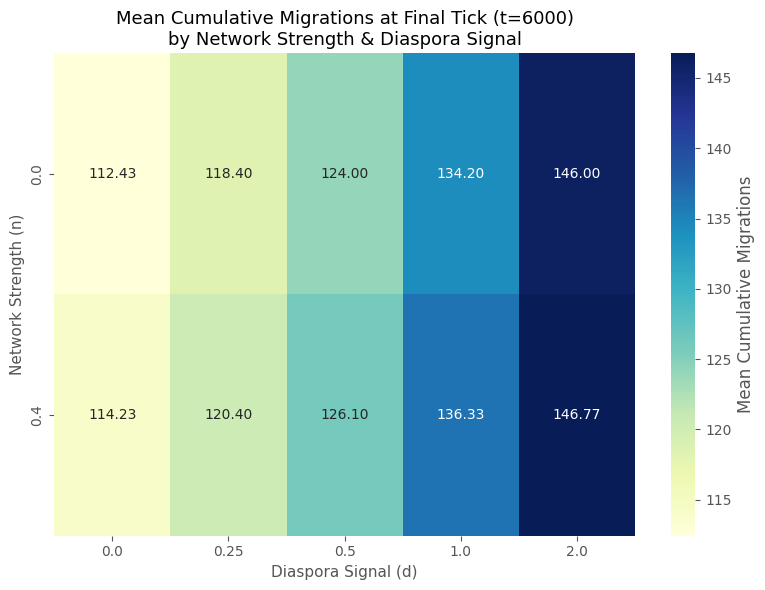

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Filter for the final timestep
final_df = df[df['ticks'] == 6000]

# 3. Create a pivot table of mean cumulative-migrations
pivot_table_cum = final_df.pivot_table(
    values='cumulative-migrations',
    index='network-strength',
    columns='diaspora-signal',
    aggfunc='mean'
)

# 4. Plot as a heatmap to show clear gradients
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table_cum, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Mean Cumulative Migrations'})
plt.title('Mean Cumulative Migrations at Final Tick (t=6000)\nby Network Strength & Diaspora Signal', fontsize=13)
plt.xlabel('Diaspora Signal (d)', fontsize=11)
plt.ylabel('Network Strength (n)', fontsize=11)
plt.tight_layout()
plt.show()

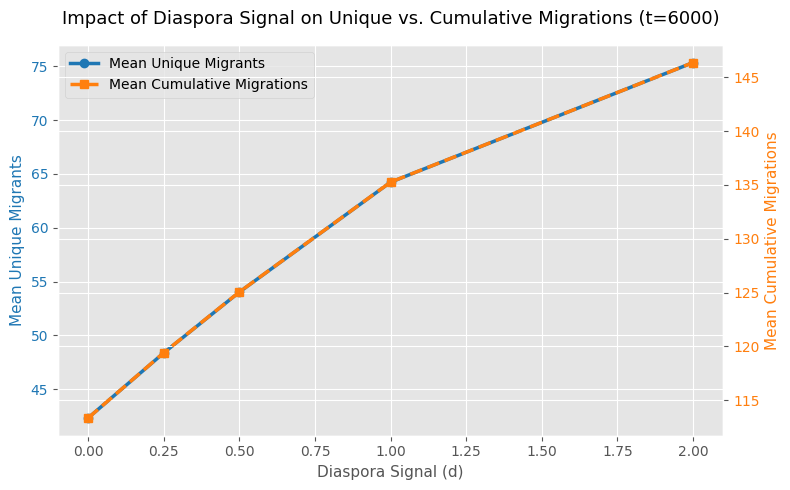

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Filter for the final timestep (t=6000)
final_df = df[df['ticks'] == 6000]

# 3. Group by diaspora-signal and average both outcomes
diaspora_grouped = final_df.groupby('diaspora-signal')[['unique-migrants', 'cumulative-migrations']].mean().reset_index()

# 4. Plot both metrics together
fig, ax1 = plt.subplots(figsize=(8, 5))
plt.style.use('ggplot')

# Plot Unique Migrants on the left y-axis
color = 'tab:blue'
ax1.set_xlabel('Diaspora Signal (d)', fontsize=11)
ax1.set_ylabel('Mean Unique Migrants', color=color, fontsize=11)
line1 = ax1.plot(diaspora_grouped['diaspora-signal'], diaspora_grouped['unique-migrants'],
                 marker='o', linewidth=2.5, color=color, label='Mean Unique Migrants')
ax1.tick_params(axis='y', labelcolor=color)

# Instantiate a second y-axis that shares the same x-axis
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Mean Cumulative Migrations', color=color, fontsize=11)
line2 = ax2.plot(diaspora_grouped['diaspora-signal'], diaspora_grouped['cumulative-migrations'],
                 marker='s', linewidth=2.5, color=color, linestyle='--', label='Mean Cumulative Migrations')
ax2.tick_params(axis='y', labelcolor=color)

# Combined legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Impact of Diaspora Signal on Unique vs. Cumulative Migrations (t=6000)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

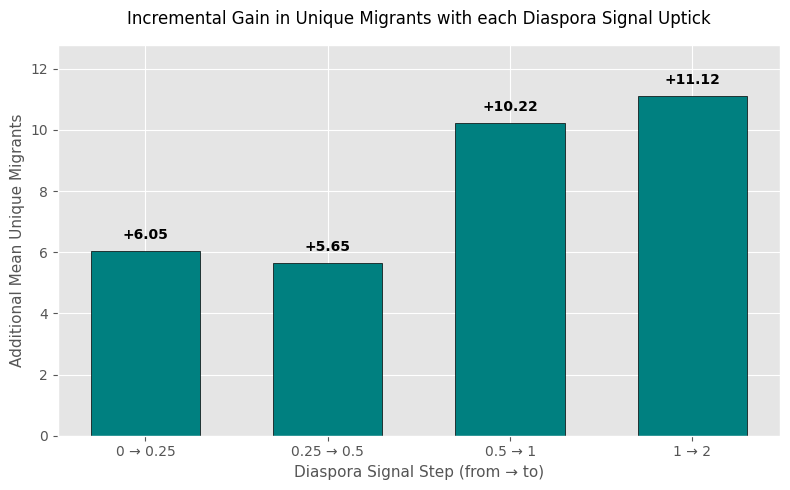

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Filter for the final timestep (t=6000)
final_df = df[df['ticks'] == 6000]

# 3. Group by diaspora-signal and average
diaspora_grouped = final_df.groupby('diaspora-signal')['unique-migrants'].mean().reset_index()

# 4. Calculate the marginal gain for each consecutive uptick
diaspora_grouped['marginal_gain'] = diaspora_grouped['unique-migrants'].diff()

# 5. Create labels for the increments (e.g., '0.00 -> 0.25')
increments = []
signals = diaspora_grouped['diaspora-signal'].tolist()
for i in range(1, len(signals)):
    increments.append(f"{signals[i-1]:g} → {signals[i]:g}")

# Remove the first row since its difference is NaN
gain_data = diaspora_grouped.dropna().copy()
gain_data['increment'] = increments

# 6. Plot the incremental gains
plt.figure(figsize=(8, 5))
plt.style.use('ggplot')

bars = plt.bar(gain_data['increment'], gain_data['marginal_gain'], color='teal', edgecolor='black', width=0.6)

# Add values on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"+{yval:.2f}", ha='center', va='bottom', fontweight='bold')

plt.title('Incremental Gain in Unique Migrants with each Diaspora Signal Uptick', fontsize=12, pad=15)
plt.xlabel('Diaspora Signal Step (from → to)', fontsize=11)
plt.ylabel('Additional Mean Unique Migrants', fontsize=11)
plt.ylim(0, gain_data['marginal_gain'].max() * 1.15)
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

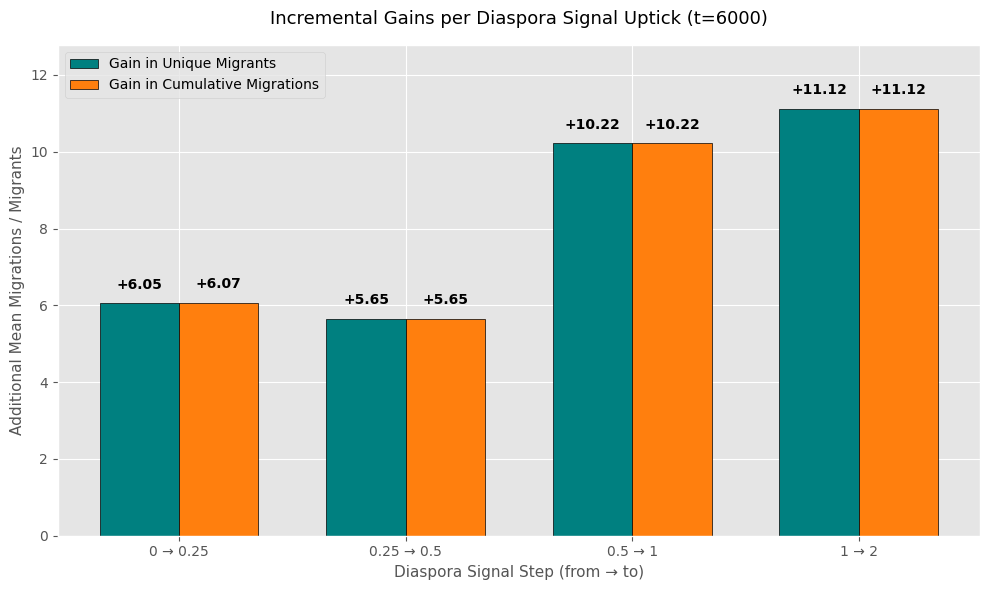

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Filter for the final timestep (t=6000)
final_df = df[df['ticks'] == 6000]

# 3. Group by diaspora-signal and average both outcomes
diaspora_grouped = final_df.groupby('diaspora-signal')[['unique-migrants', 'cumulative-migrations']].mean().reset_index()

# 4. Calculate marginal gains
diaspora_grouped['unique_gain'] = diaspora_grouped['unique-migrants'].diff()

diaspora_grouped['cumulative_gain'] = diaspora_grouped['cumulative-migrations'].diff()

# 5. Prepare labels for the intervals
signals = diaspora_grouped['diaspora-signal'].tolist()
increments = [f"{signals[i-1]:g} → {signals[i]:g}" for i in range(1, len(signals))]

gain_data = diaspora_grouped.dropna().copy()
gain_data['increment'] = increments

# 6. Plot side-by-side bar chart
plt.figure(figsize=(10, 6))
plt.style.use('ggplot')

x = np.arange(len(increments))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, gain_data['unique_gain'], width, label='Gain in Unique Migrants', color='teal', edgecolor='black')
bars2 = ax.bar(x + width/2, gain_data['cumulative_gain'], width, label='Gain in Cumulative Migrations', color='tab:orange', edgecolor='black')

# Add values on top of the bars
for bar in bars1:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"+{yval:.2f}", ha='center', va='bottom', fontweight='bold', color='darksize' if 'darksize' in globals() else 'black')

for bar in bars2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"+{yval:.2f}", ha='center', va='bottom', fontweight='bold', color='black')

ax.set_title('Incremental Gains per Diaspora Signal Uptick (t=6000)', fontsize=13, pad=15)
ax.set_xlabel('Diaspora Signal Step (from → to)', fontsize=11)
ax.set_ylabel('Additional Mean Migrations / Migrants', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(increments)
ax.legend(loc='upper left')
ax.set_ylim(0, max(gain_data['cumulative_gain'].max(), gain_data['unique_gain'].max()) * 1.15)

plt.tight_layout()
plt.show()

Interval: 0 → 0.25 | Unique Gain: 6.0500 | Cumulative Gain: 6.0667
Interval: 0.25 → 0.5 | Unique Gain: 5.6500 | Cumulative Gain: 5.6500
Interval: 0.5 → 1 | Unique Gain: 10.2167 | Cumulative Gain: 10.2167
Interval: 1 → 2 | Unique Gain: 11.1167 | Cumulative Gain: 11.1167


<Figure size 1000x600 with 0 Axes>

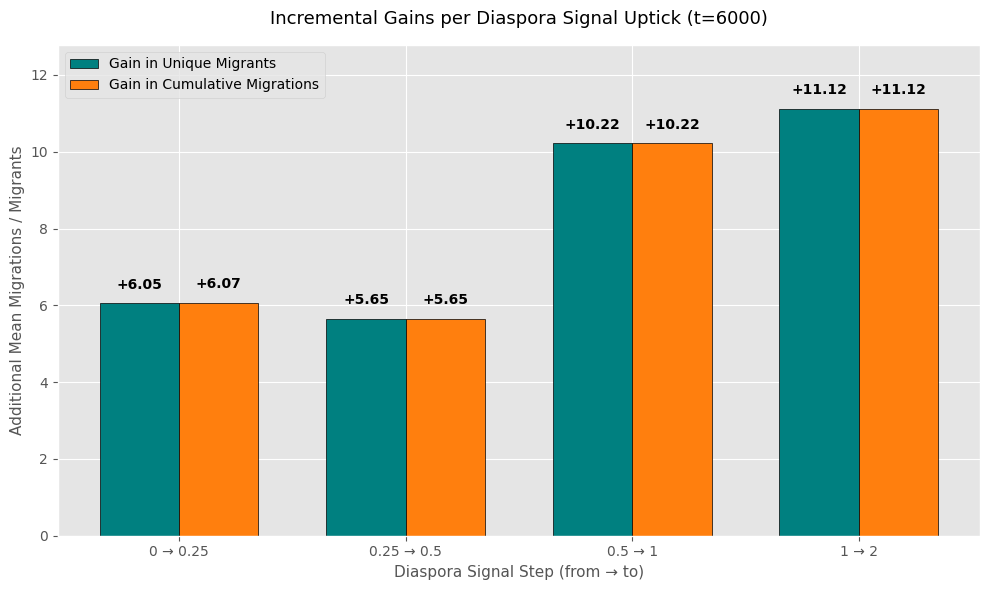

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load and clean
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# Filter for final tick
final_df = df[df['ticks'] == 6000]

# Group and calculate means separately to be absolutely sure
unique_means = final_df.groupby('diaspora-signal')['unique-migrants'].mean()
cumulative_means = final_df.groupby('diaspora-signal')['cumulative-migrations'].mean()

# Calculate correct incremental gains (differences)
unique_gains = unique_means.diff().dropna()
cumulative_gains = cumulative_means.diff().dropna()

signals = sorted(final_df['diaspora-signal'].unique())
increments = [f"{signals[i-1]:g} → {signals[i]:g}" for i in range(1, len(signals))]

# Print the actual values to verify
for inc, u_g, c_g in zip(increments, unique_gains, cumulative_gains):
    print(f"Interval: {inc} | Unique Gain: {u_g:.4f} | Cumulative Gain: {c_g:.4f}")

# Plot the correct side-by-side bar chart
plt.figure(figsize=(10, 6))
plt.style.use('ggplot')

x = np.arange(len(increments))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, unique_gains, width, label='Gain in Unique Migrants', color='teal', edgecolor='black')
bars2 = ax.bar(x + width/2, cumulative_gains, width, label='Gain in Cumulative Migrations', color='tab:orange', edgecolor='black')

for bar in bars1:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"+{yval:.2f}", ha='center', va='bottom', fontweight='bold')

for bar in bars2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"+{yval:.2f}", ha='center', va='bottom', fontweight='bold')

ax.set_title('Incremental Gains per Diaspora Signal Uptick (t=6000)', fontsize=13, pad=15)
ax.set_xlabel('Diaspora Signal Step (from → to)', fontsize=11)
ax.set_ylabel('Additional Mean Migrations / Migrants', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(increments)
ax.legend(loc='upper left')
ax.set_ylim(0, max(cumulative_gains.max(), unique_gains.max()) * 1.15)

plt.tight_layout()
plt.show()

Baseline Values (n=0.0, d=0.0):
  Mean Unique Migrants: 41.47
  Mean Cumulative Migrations: 112.43



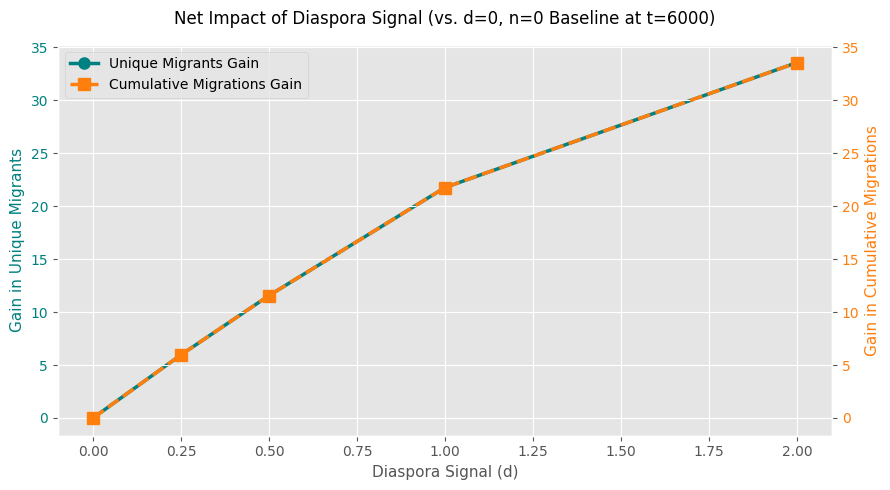

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Filter for final tick (t=6000)
final_df = df[df['ticks'] == 6000]

# 3. Group by network-strength and diaspora-signal to find the means
grouped = final_df.groupby(['network-strength', 'diaspora-signal'])[['unique-migrants', 'cumulative-migrations']].mean()

# 4. Extract baseline values: no network effect (n=0.0) and no diaspora signal (d=0.0)
base_unique = grouped.loc[(0.0, 0.0), 'unique-migrants']
base_cumulative = grouped.loc[(0.0, 0.0), 'cumulative-migrations']

print(f"Baseline Values (n=0.0, d=0.0):")
print(f"  Mean Unique Migrants: {base_unique:.2f}")
print(f"  Mean Cumulative Migrations: {base_cumulative:.2f}\n")

# 5. Extract means for n=0.0 across all diaspora signal values
no_net_df = grouped.loc[0.0].reset_index()

# Calculate net gains over the pure baseline
no_net_df['unique_gain'] = no_net_df['unique-migrants'] - base_unique
no_net_df['cumulative_gain'] = no_net_df['cumulative-migrations'] - base_cumulative

# 6. Plot the results
fig, ax1 = plt.subplots(figsize=(9, 5))
plt.style.use('ggplot')

color = 'teal'
ax1.set_xlabel('Diaspora Signal (d)', fontsize=11)
ax1.set_ylabel('Gain in Unique Migrants', color=color, fontsize=11)
line1 = ax1.plot(no_net_df['diaspora-signal'], no_net_df['unique_gain'],
                 marker='o', markersize=8, linewidth=2.5, color=color, label='Unique Migrants Gain')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Gain in Cumulative Migrations', color=color, fontsize=11)
line2 = ax2.plot(no_net_df['diaspora-signal'], no_net_df['cumulative_gain'],
                 marker='s', markersize=8, linewidth=2.5, color=color, linestyle='--', label='Cumulative Migrations Gain')
ax2.tick_params(axis='y', labelcolor=color)

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Net Impact of Diaspora Signal (vs. d=0, n=0 Baseline at t=6000)', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

Timestep (t) Mean First-Time Migrants  Median Standard Deviation Min – Max Range Mean Cumulative Migrations
     t = 500                    14.93      15               3.64          5 – 21                      21.33
    t = 1000                    26.00      27               4.05         18 – 35                      37.80
    t = 2000                    40.73      40               4.78         31 – 50                      64.80
    t = 6000                    49.30      50               5.31         41 – 58                     120.40


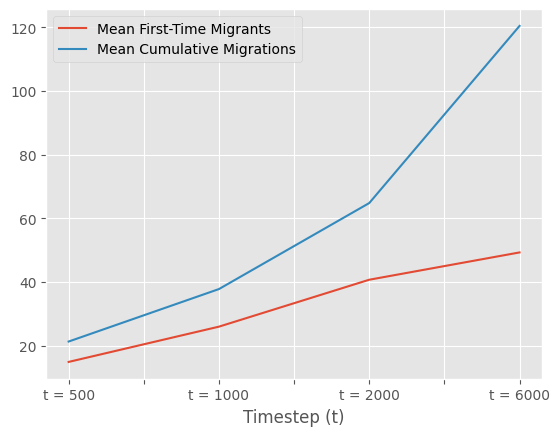

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the BehaviorSpace output CSV file (skipping NetLogo header metadata)
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)

# 2. Filter for baseline conditions: network-strength = 0.0 and diaspora-signal = 0.0
filtered_df = df[(df['network-strength'] == 0.4) & (df['diaspora-signal'] == 0.25)]

# 3. Specify target timesteps
timesteps = [500, 1000, 2000, 6000]

# 4. Calculate summary statistics across all 30 runs per timestep
summary_data = []
for t in timesteps:
    sub = filtered_df[filtered_df['ticks'] == t]
    um = sub['unique-migrants']
    cm = sub['cumulative-migrations']

    summary_data.append({
        'Timestep (t)': f't = {t}',
        'Mean First-Time Migrants': f"{um.mean():.2f}",
        'Median': int(um.median()),
        'Standard Deviation': f"{um.std():.2f}",
        'Min – Max Range': f"{um.min()} – {um.max()}",
        'Mean Cumulative Migrations': f"{cm.mean():.2f}"
    })

# 5. Convert to pandas DataFrame and output table
summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))
plt.style.use('ggplot')

# Convert formatted string columns to numeric for plotting
summary_df["Mean First-Time Migrants"] = pd.to_numeric(summary_df["Mean First-Time Migrants"])
summary_df["Mean Cumulative Migrations"] = pd.to_numeric(summary_df["Mean Cumulative Migrations"])

# Corrected the missing comma and the typo in the column name
summary_df.plot(x='Timestep (t)', y=["Mean First-Time Migrants", "Mean Cumulative Migrations"], kind='line')
plt.show()

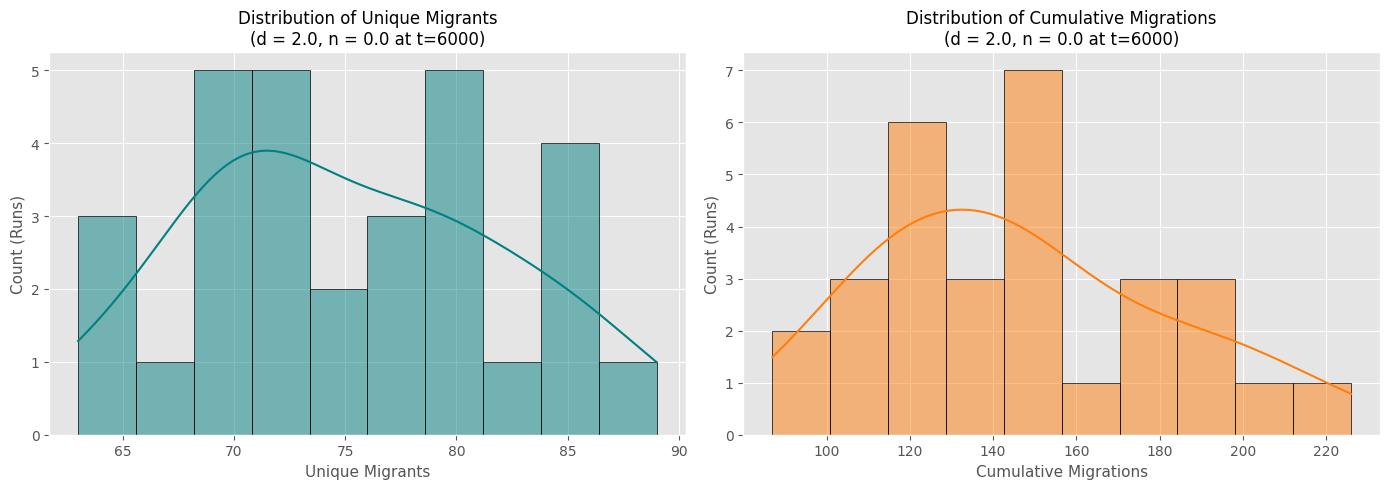

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]

# 2. Filter for final tick (t=6000), no network strength (n=0.0), and a strong diaspora signal (d=2.0)
target_df = df[(df['ticks'] == 6000) & (df['network-strength'] == 0.0) & (df['diaspora-signal'] == 2.0)]

# 3. Plot the distributions side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
plt.style.use('ggplot')

# Unique Migrants Distribution
sns.histplot(target_df['unique-migrants'], kde=True, ax=axes[0], color='teal', bins=10, edgecolor='black')
axes[0].set_title('Distribution of Unique Migrants\n(d = 2.0, n = 0.0 at t=6000)', fontsize=12)
axes[0].set_xlabel('Unique Migrants', fontsize=11)
axes[0].set_ylabel('Count (Runs)', fontsize=11)

# Cumulative Migrations Distribution
sns.histplot(target_df['cumulative-migrations'], kde=True, ax=axes[1], color='tab:orange', bins=10, edgecolor='black')
axes[1].set_title('Distribution of Cumulative Migrations\n(d = 2.0, n = 0.0 at t=6000)', fontsize=12)
axes[1].set_xlabel('Cumulative Migrations', fontsize=11)
axes[1].set_ylabel('Count (Runs)', fontsize=11)

plt.tight_layout()
plt.show()

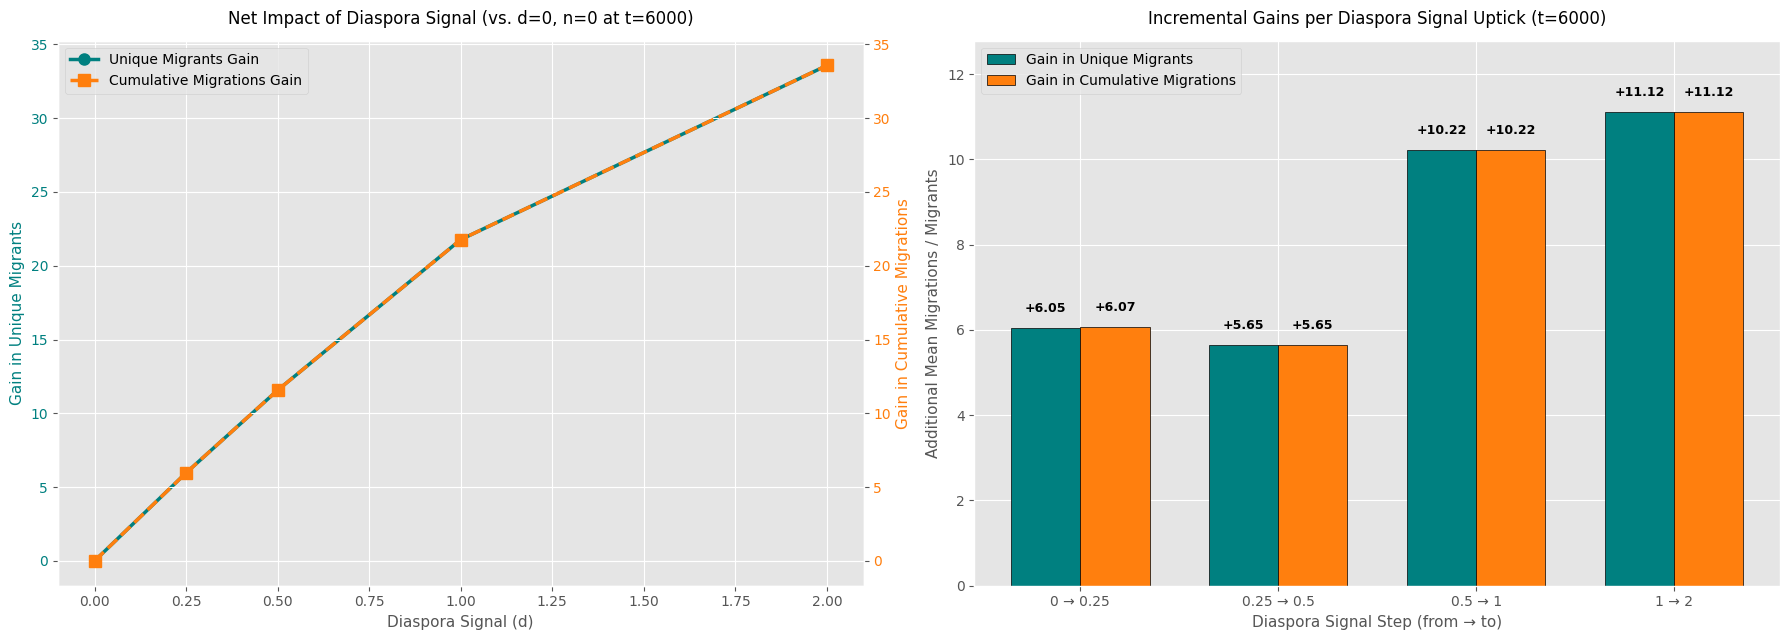

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df.columns = [c.strip() for c in df.columns]
final_df = df[df['ticks'] == 6000]

# -----------------------------------------------------
# Plot 1: Net Impact of Diaspora Signal (vs. Baseline)
# -----------------------------------------------------
fig, ax1 = plt.subplots(figsize=(9, 5))
plt.style.use('ggplot')

grouped = final_df.groupby(['network-strength', 'diaspora-signal'])[['unique-migrants', 'cumulative-migrations']].mean()
base_unique = grouped.loc[(0.0, 0.0), 'unique-migrants']
base_cumulative = grouped.loc[(0.0, 0.0), 'cumulative-migrations']
no_net_df = grouped.loc[0.0].reset_index()

no_net_df['unique_gain'] = no_net_df['unique-migrants'] - base_unique
no_net_df['cumulative_gain'] = no_net_df['cumulative-migrations'] - base_cumulative

color = 'teal'
ax1.set_xlabel('Diaspora Signal (d)', fontsize=11)
ax1.set_ylabel('Gain in Unique Migrants', color=color, fontsize=11)
line1 = ax1.plot(no_net_df['diaspora-signal'], no_net_df['unique_gain'],
                 marker='o', markersize=8, linewidth=2.5, color=color, label='Unique Migrants Gain')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Gain in Cumulative Migrations', color=color, fontsize=11)
line2 = ax2.plot(no_net_df['diaspora-signal'], no_net_df['cumulative_gain'],
                 marker='s', markersize=8, linewidth=2.5, color=color, linestyle='--', label='Cumulative Migrations Gain')
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')
plt.title('Net Impact of Diaspora Signal (vs. d=0, n=0 Baseline at t=6000)', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

# -----------------------------------------------------
# Plot 2: Side-by-Side Incremental Gains per Step
# -----------------------------------------------------
unique_means = final_df.groupby('diaspora-signal')['unique-migrants'].mean()
cumulative_means = final_df.groupby('diaspora-signal')['cumulative-migrations'].mean()
unique_gains = unique_means.diff().dropna()
cumulative_gains = cumulative_means.diff().dropna()

signals = sorted(final_df['diaspora-signal'].unique())
increments = [f"{signals[i-1]:g} → {signals[i]:g}" for i in range(1, len(signals))]

x = np.arange(len(increments))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, unique_gains, width, label='Gain in Unique Migrants', color='teal', edgecolor='black')
bars2 = ax.bar(x + width/2, cumulative_gains, width, label='Gain in Cumulative Migrations', color='tab:orange', edgecolor='black')

for bar in bars1:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"+{yval:.2f}", ha='center', va='bottom', fontweight='bold')

for bar in bars2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"+{yval:.2f}", ha='center', va='bottom', fontweight='bold')

ax.set_title('Incremental Gains per Diaspora Signal Uptick (t=6000)', fontsize=12, pad=15)
ax.set_xlabel('Diaspora Signal Step (from → to)', fontsize=11)
ax.set_ylabel('Additional Mean Migrations / Migrants', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(increments)
ax.legend(loc='upper left')
ax.set_ylim(0, max(cumulative_gains.max(), unique_gains.max()) * 1.15)
plt.tight_layout()
plt.show()

In [71]:
import pandas as pd

# Load dataset
df_colors = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_colors.columns = [c.strip() for c in df_colors.columns]

# Filter for baseline network (n=0.0) and key timesteps
baseline_df = df_colors[df_colors['network-strength'] == 0.0]
color_cols = [c for c in baseline_df.columns if 'color' in c]
timesteps = [500, 1000, 2000, 6000]

# Let's clean up column names for display (e.g. 'count turtles with [color = cyan]' -> 'cyan')
clean_cols = [c.split('=')[-1].replace(']', '').strip() for c in color_cols]

records = []
for t in timesteps:
    t_df = baseline_df[baseline_df['ticks'] == t]
    grouped = t_df.groupby('diaspora-signal')[color_cols].mean()
    # Subtract d=0.0 to find absolute shift
    diff = grouped.sub(grouped.loc[0.0], axis=1)
    diff.columns = clean_cols

    # Restructure for a single compact DataFrame
    for d_val in [0.25, 0.50, 1.00, 2.00]:
        row = {'timestep': t, 'diaspora': d_val}
        row.update(diff.loc[d_val].to_dict())
        records.append(row)

progression_df = pd.DataFrame(records)
print("=== Demographic Progression: Change in Mean Agent Counts vs. d=0.0 Baseline ===")
print(progression_df.to_string(index=False, formatters={c: '{:+.2f}'.format for c in clean_cols}))

=== Demographic Progression: Change in Mean Agent Counts vs. d=0.0 Baseline ===
 timestep  diaspora   cyan  green yellow   red orange
      500      0.25  -0.40  +0.40  -0.13 +0.13  +0.00
      500      0.50  -0.70  +0.70  -0.53 +0.53  +0.00
      500      1.00  -1.33  +1.33  -0.87 +0.87  +0.00
      500      2.00  -2.73  +2.73  -1.47 +1.47  +0.00
     1000      0.25  -0.83  +0.83  -0.60 +0.60  +0.00
     1000      0.50  -1.50  +1.50  -0.80 +0.80  +0.00
     1000      1.00  -3.17  +3.17  -1.40 +1.40  +0.00
     1000      2.00  -5.53  +5.53  -2.87 +2.87  +0.00
     2000      0.25  -1.77  +1.77  -0.70 +0.70  +0.00
     2000      0.50  -3.73  +3.73  -1.40 +1.40  +0.00
     2000      1.00  -6.97  +6.97  -2.47 +2.47  +0.00
     2000      2.00 -13.17 +13.17  -4.10 +4.10  +0.00
     6000      0.25  -5.97  +5.97  -1.67 +1.67  +0.00
     6000      0.50 -11.57 +11.57  -3.00 +3.00  +0.00
     6000      1.00 -21.77 +21.77  -5.37 +5.37  +0.00
     6000      2.00 -33.57 +33.57  -8.50 +8.50  +0.00


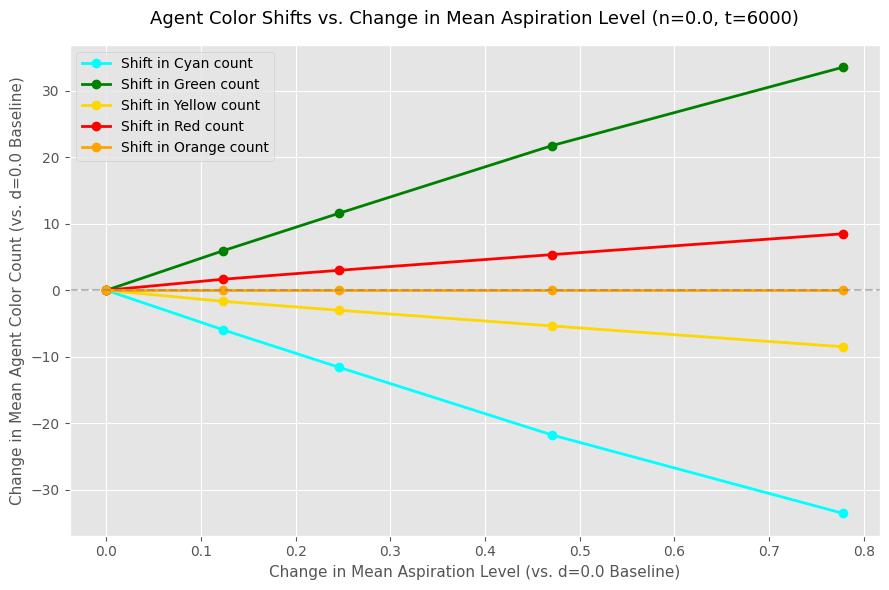

In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df_colors = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_colors.columns = [c.strip() for c in df_colors.columns]

# 2. Filter for baseline network (n=0.0) at the final timestep (t=6000) where the effect is most pronounced
baseline_df = df_colors[(df_colors['network-strength'] == 0.0) & (df_colors['ticks'] == 6000)]

# Get mean color counts and mean aspiration levels
color_cols = [c for c in baseline_df.columns if 'color' in c]
clean_cols = [c.split('=')[-1].replace(']', '').strip() for c in color_cols]

grouped = baseline_df.groupby('diaspora-signal')[['mean-aspiration-level'] + color_cols].mean()

# Calculate change compared to d = 0.0 baseline
changes = grouped.sub(grouped.loc[0.0], axis=1).reset_index()
changes.rename(columns=dict(zip(color_cols, clean_cols)), inplace=True)
changes.rename(columns={'mean-aspiration-level': 'delta_aspiration'}, inplace=True)

# 3. Plot the relationship
plt.figure(figsize=(9, 6))
plt.style.use('ggplot')

for color_name in ['cyan', 'green', 'yellow', 'red', 'orange']:
    plt.plot(
        changes['delta_aspiration'],
        changes[color_name],
        marker='o',
        linewidth=2,
        label=f'Shift in {color_name.capitalize()} count',
        color=color_name if color_name != 'yellow' else 'gold'  # yellow is hard to see on light background
    )

plt.title('Agent Color Shifts vs. Change in Mean Aspiration Level (n=0.0, t=6000)', fontsize=13, pad=15)
plt.xlabel('Change in Mean Aspiration Level (vs. d=0.0 Baseline)', fontsize=11)
plt.ylabel('Change in Mean Agent Color Count (vs. d=0.0 Baseline)', fontsize=11)
plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

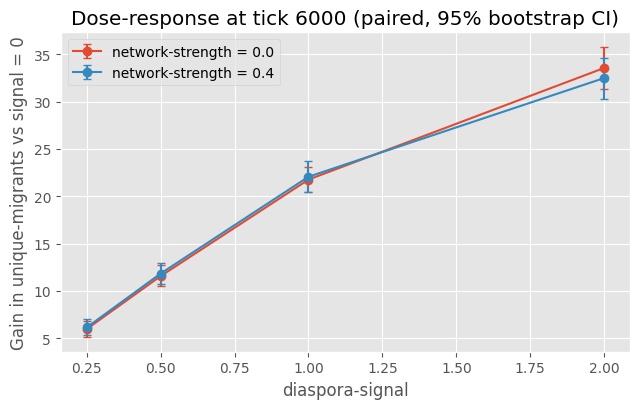

In [50]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for n, c in zip(sorted(d[NET].unique()), ['C0', 'C1']):
    s = tab[tab.net == n]
    ax.errorbar(s.dia, s.gain, yerr=[s.gain - s.lo, s.hi - s.gain], marker='o', capsize=3, color=c, label=f'network-strength = {n}')
ax.set_xlabel('diaspora-signal'); ax.set_ylabel(f'Gain in {OUTCOME} vs signal = 0')
ax.set_title(f'Dose-response at tick {T_END} (paired, 95% bootstrap CI)'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

## 2. Adoption curves (mean ± 95% band across seeds)

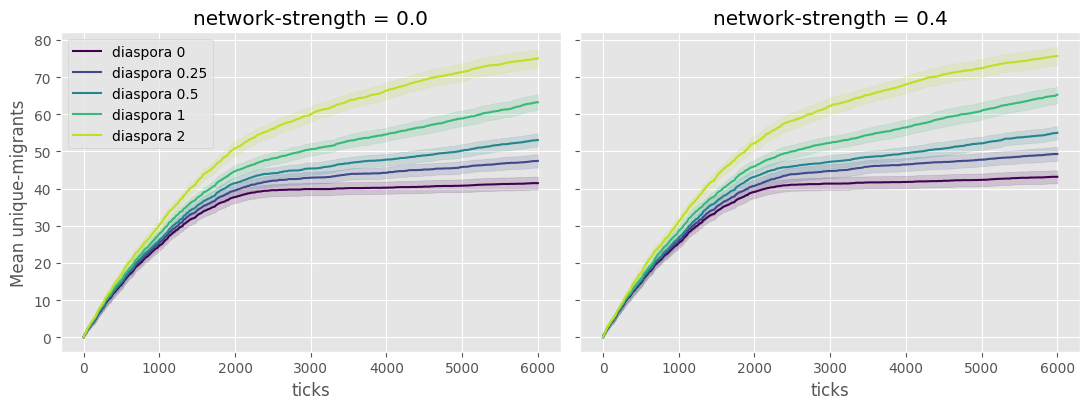

In [51]:
def band(n, dv):
    X = P.loc[(n, dv)]
    m = X.mean(); se = X.std() / np.sqrt(len(X))
    return m, m - 1.96 * se, m + 1.96 * se

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
cols = plt.cm.viridis(np.linspace(0, .9, d[DIA].nunique()))
for ax, n in zip(axes, sorted(d[NET].unique())):
    for c, dv in zip(cols, sorted(d[DIA].unique())):
        m, lo, hi = band(n, dv)
        ax.plot(m.index, m.values, color=c, label=f'diaspora {dv:g}')
        ax.fill_between(m.index, lo, hi, color=c, alpha=.15)
    ax.set_title(f'network-strength = {n}'); ax.set_xlabel('ticks')
axes[0].set_ylabel(f'Mean {OUTCOME}'); axes[0].legend(loc='upper left')
plt.tight_layout(); plt.show()

## 3. When does the pull act? Paired gain over time

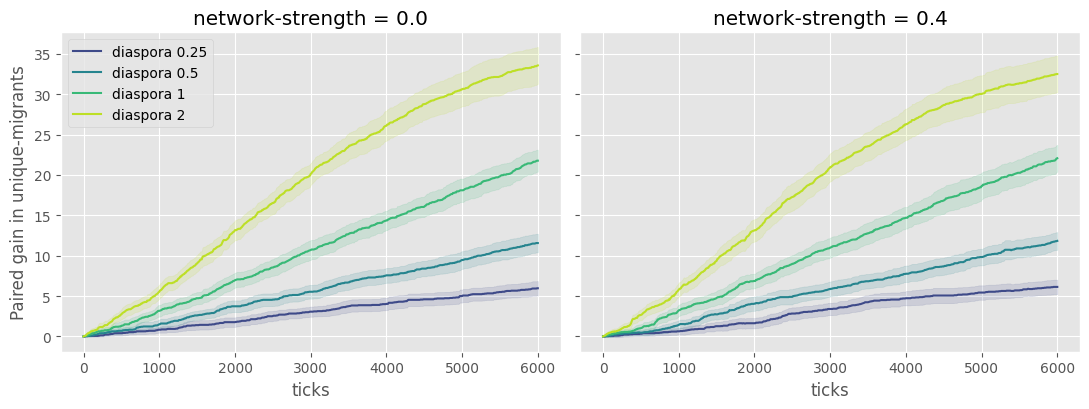

,net,dia,share of final gain by t=500,share of final gain by t=1000,share of final gain by t=2000,share of final gain by t=3000,share of final gain by t=4000
0,0.0,0.25,0.07,0.14,0.30,0.51,0.68
1,0.0,0.50,0.06,0.13,0.32,0.48,0.65
2,0.0,1.00,0.06,0.15,0.32,0.49,0.66
3,0.0,2.00,0.08,0.16,0.39,0.60,0.78
4,0.4,0.25,0.05,0.10,0.27,0.55,0.77
5,0.4,0.50,0.04,0.12,0.34,0.50,0.66
6,0.4,1.00,0.05,0.15,0.31,0.50,0.67
7,0.4,2.00,0.08,0.18,0.40,0.65,0.81


In [52]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, n in zip(axes, sorted(d[NET].unique())):
    for c, dv in zip(cols[1:], sorted(d[DIA].unique())[1:]):
        g = (P.loc[(n, dv)] - P.loc[(n, 0.0)])
        m = g.mean(); se = g.std() / np.sqrt(len(g))
        ax.plot(m.index, m.values, color=c, label=f'diaspora {dv:g}')
        ax.fill_between(m.index, m - 1.96 * se, m + 1.96 * se, color=c, alpha=.15)
    ax.set_title(f'network-strength = {n}'); ax.set_xlabel('ticks')
axes[0].set_ylabel(f'Paired gain in {OUTCOME}'); axes[0].legend(loc='upper left')
plt.tight_layout(); plt.show()

rows = []
for n in sorted(d[NET].unique()):
    for dv in sorted(d[DIA].unique())[1:]:
        g = (P.loc[(n, dv)] - P.loc[(n, 0.0)]).mean()
        rows.append(dict(net=n, dia=dv, **{f'share of final gain by t={t}': g[t] / g[T_END] for t in (500, 1000, 2000, 3000, 4000) if t in g.index}))
pd.DataFrame(rows).round(2)

## 4. Timing: time to 50% / 90% of own final adoption
Note: relative to each arm's own final value, so a *late* extra pull shifts these later even though absolute adoption is higher at every tick.

                     t50             t90        
network-strength     0.0     0.4     0.0     0.4
diaspora-signal                                 
0.00               780.0   780.0  1945.0  1935.0
0.25               905.0   910.0  2635.0  2580.0
0.50              1060.0  1030.0  3930.0  4135.0
1.00              1165.0  1120.0  4555.0  4445.0
2.00              1315.0  1250.0  4120.0  4035.0


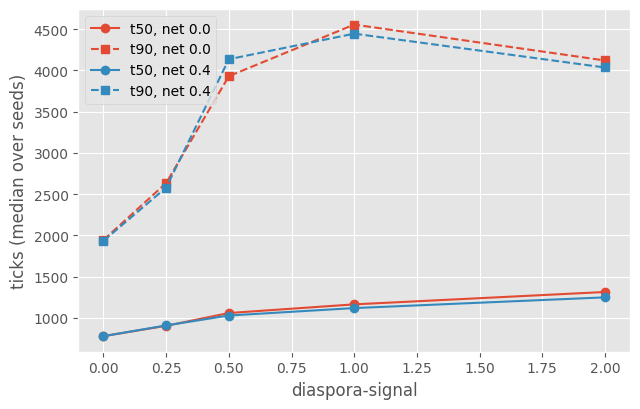

In [53]:
def t_to(row, q):
    f = row.iloc[-1]
    return np.nan if f <= 0 else row.index[(row >= q * f).values.argmax()]

T = P.apply(lambda r: pd.Series({'t50': t_to(r, .5), 't90': t_to(r, .9)}), axis=1).reset_index()
tt = T.groupby([NET, DIA])[['t50', 't90']].median().unstack(0)
print(tt)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for n, c in zip(sorted(d[NET].unique()), ['C0', 'C1']):
    s = T[T[NET] == n].groupby(DIA)[['t50', 't90']].median()
    ax.plot(s.index, s.t50, 'o-', color=c, label=f't50, net {n}')
    ax.plot(s.index, s.t90, 's--', color=c, label=f't90, net {n}')
ax.set_xlabel('diaspora-signal'); ax.set_ylabel('ticks (median over seeds)'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

## 5. Channel accounting at the final tick

In [54]:
ch = ['cumulative-net-boost', 'cumulative-peer-pressure', 'cumulative-diaspora-pull']
last = d[d.ticks == T_END].groupby([NET, DIA])[ch + ['mean-asp-social', 'ever-in-zone-share', 'cumulative-migrations']].mean().round(2)
last

cumulative-net-boost  \
network-strength diaspora-signal                         
0.0              0.00                             0.00   
                 0.25                             0.00   
                 0.50                             0.00   
                 1.00                             0.00   
                 2.00                             0.00   
0.4              0.00                            47.03   
                 0.25                            53.37   
                 0.50                            59.47   
                 1.00                            70.79   
                 2.00                            81.41   

                                  cumulative-peer-pressure  \
network-strength diaspora-signal                             
0.0              0.00                                 0.00   
                 0.25                                 0.00   
                 0.50                                 0.00   
                 1.00                                 0.00   
                 2.00                                 0.00   
0.4              0.00                                 0.36   
                 0.25                                 2.38   
                 0.50                                 4.62   
                 1.00                                 8.86   
                 2.00                                10.70   

                                  cumulative-diaspora-pull  mean-asp-social  \
network-strength diaspora-signal                                              
0.0              0.00                                 0.00             4.96   
                 0.25                               169.05             5.77   
                 0.50                               345.94             6.55   
                 1.00                               721.92             7.94   
                 2.00                              1541.75             9.73   
0.4              0.00                                 0.00             5.19   
                 0.25                               171.32             6.03   
                 0.50                               350.41             6.82   
                 1.00                               731.24             8.21   
                 2.00                              1557.26             9.83   

                                  ever-in-zone-share  cumulative-migrations  
network-strength diaspora-signal                                             
0.0              0.00                           0.58                 112.43  
                 0.25                           0.61                 118.40  
                 0.50                           0.64                 124.00  
                 1.00                           0.69                 134.20  
                 2.00                           0.75                 146.00  
0.4              0.00                           0.59                 114.23  
                 0.25                           0.62                 120.40  
                 0.50                           0.65                 126.10  
                 1.00                           0.70                 136.33  
                 2.00                           0.75                 146.77

In [55]:
# Control check: arms with diaspora-signal = 0 should match earlier contagion runs (33.0 / 33.67 at 6000 ticks)
print(fin.loc[(0.0, 0.0)].mean().round(2), fin.loc[(0.4, 0.0)].mean().round(2))

41.47 43.17


## 6. Aspiration versus ability: what does the diaspora pull change?
Ability reporters should be identical across diaspora arms if the pull acts only on aspiration. The ratio of extra migrants to extra social aspiration shows how steadily aspiration is converted into migration.

In [56]:
net0 = d[d[NET] == 0.0]
G = net0.groupby([DIA, 'ticks'])[['mean-ability-level', 'share-high-ability', 'mean-asp-social', 'mean-aspiration-level', OUTCOME]].mean()
checkpoints = [500, 1000, 2000, 3000, 4000, T_END]
print("Spread of mean ability across diaspora arms (max - min):")
print((G['mean-ability-level'].unstack(0).max(axis=1) - G['mean-ability-level'].unstack(0).min(axis=1)).loc[checkpoints].round(3))

base = G.xs(0.0, level=DIA)
rows = []
for dv in sorted(d[DIA].unique())[1:]:
    x = G.xs(dv, level=DIA) - base
    for t in checkpoints:
        rows.append(dict(dia=dv, ticks=t, extra_migrants=x.loc[t, OUTCOME], extra_asp_social=x.loc[t, 'mean-asp-social'],
                         migrants_per_asp_point=x.loc[t, OUTCOME] / x.loc[t, 'mean-asp-social']))
conv = pd.DataFrame(rows)
conv.round(2)

Spread of mean ability across diaspora arms (max - min):
ticks
500     0.0
1000    0.0
2000    0.0
3000    0.0
4000    0.0
6000    0.0
dtype: float64


,dia,ticks,extra_migrants,extra_asp_social,migrants_per_asp_point
0,0.25,500,0.40,0.05,7.72
1,0.25,1000,0.83,0.11,7.50
2,0.25,2000,1.77,0.24,7.22
3,0.25,3000,3.07,0.39,7.94
4,0.25,4000,4.03,0.53,7.64
5,0.25,6000,5.97,0.81,7.36
6,0.50,500,0.70,0.10,6.76
7,0.50,1000,1.50,0.22,6.76
8,0.50,2000,3.73,0.49,7.67
9,0.50,3000,5.53,0.77,7.22


In [61]:
import pandas as pd

# Load the dataset and inspect columns
df_temp = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_temp.columns = [c.strip() for c in df_temp.columns]

# Let's find columns related to high-ability and low-ability migrants or other turtle counts
ability_cols = [c for c in df_temp.columns if 'ability' in c or 'migrant' in c or 'color' in c]
print("Relevant Columns:", ability_cols)


Relevant Columns: ['initial-ability-level', 'unique-migrants', 'mean-ability-level', 'share-high-ability', 'count turtles with [color = cyan]', 'count turtles with [color = green]', 'count turtles with [color = yellow]', 'count turtles with [color = red]', 'count turtles with [color = orange]']


In [62]:
# Calculate the breakdown of high-ability and other groups at early timesteps (e.g., tick 10, 20, 50, 100)
early_df = df_temp[df_temp['ticks'].isin([0, 10, 20, 30, 40, 50, 100])].groupby('ticks').mean(numeric_only=True)

# Display the progression to see who crosses first
metrics = [c for c in ['unique-migrants', 'share-high-ability', 'mean-ability-level'] if c in early_df.columns]
display(early_df[metrics].head(10))

,unique-migrants,share-high-ability,mean-ability-level
ticks,,,
0,0.000000,0.503333,5.020507
10,0.636667,0.505500,5.030505
20,0.953333,0.507500,5.040338
30,1.303333,0.509500,5.049995
40,1.733333,0.512333,5.059695
50,2.166667,0.515333,5.069342
100,3.690000,0.525167,5.117177


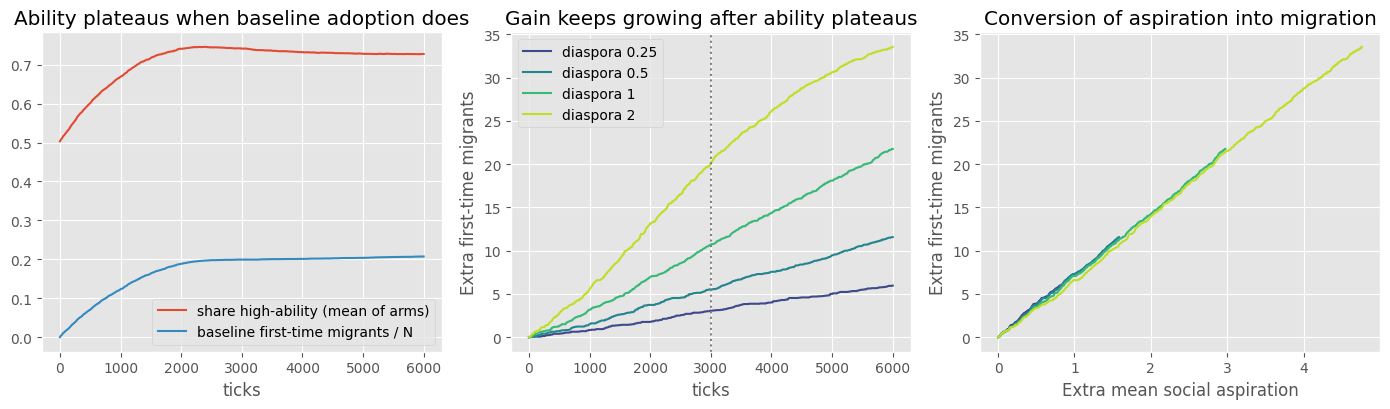

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
ab = G['share-high-ability'].unstack(0)
axes[0].plot(ab.index, ab.mean(axis=1), color='C0', label='share high-ability (mean of arms)')
axes[0].plot(base.index, base[OUTCOME] / 200, color='C1', label='baseline first-time migrants / N')
axes[0].set_xlabel('ticks'); axes[0].set_title('Ability plateaus when baseline adoption does'); axes[0].legend(loc='lower right')
for c, dv in zip(cols[1:], sorted(d[DIA].unique())[1:]):
    x = G.xs(dv, level=DIA) - base
    axes[1].plot(x.index, x[OUTCOME], color=c, label=f'diaspora {dv:g}')
    axes[2].plot(x['mean-asp-social'], x[OUTCOME], color=c, label=f'diaspora {dv:g}')
axes[1].set_xlabel('ticks'); axes[1].set_ylabel('Extra first-time migrants'); axes[1].set_title('Gain keeps growing after ability plateaus')
axes[1].axvline(3000, color='grey', ls=':'); axes[1].legend(loc='upper left')
axes[2].set_xlabel('Extra mean social aspiration'); axes[2].set_ylabel('Extra first-time migrants'); axes[2].set_title('Conversion of aspiration into migration')
plt.tight_layout(); plt.show()

In [58]:
# Between-seed correlation at the final tick, baseline arm (no pull)
f = net0[(net0.ticks == T_END) & (net0[DIA] == 0.0)]
f[[OUTCOME, 'mean-aspiration-level', 'mean-ability-level', 'share-high-ability', 'mean-asp-social']].corr()[OUTCOME].round(2)

,unique-migrants
unique-migrants,1.00
mean-aspiration-level,0.15
mean-ability-level,-0.03
share-high-ability,0.03
mean-asp-social,0.09


Summary Metrics at t=6000 (n=0.0):


,diaspora-signal,unique-migrants,mean-aspiration-level,mean-ability-level,share-high-ability
0,0.00,41.467,6.330,6.1,0.727
1,0.25,47.433,6.454,6.1,0.727
2,0.50,53.033,6.576,6.1,0.727
3,1.00,63.233,6.801,6.1,0.727
4,2.00,75.033,7.108,6.1,0.727


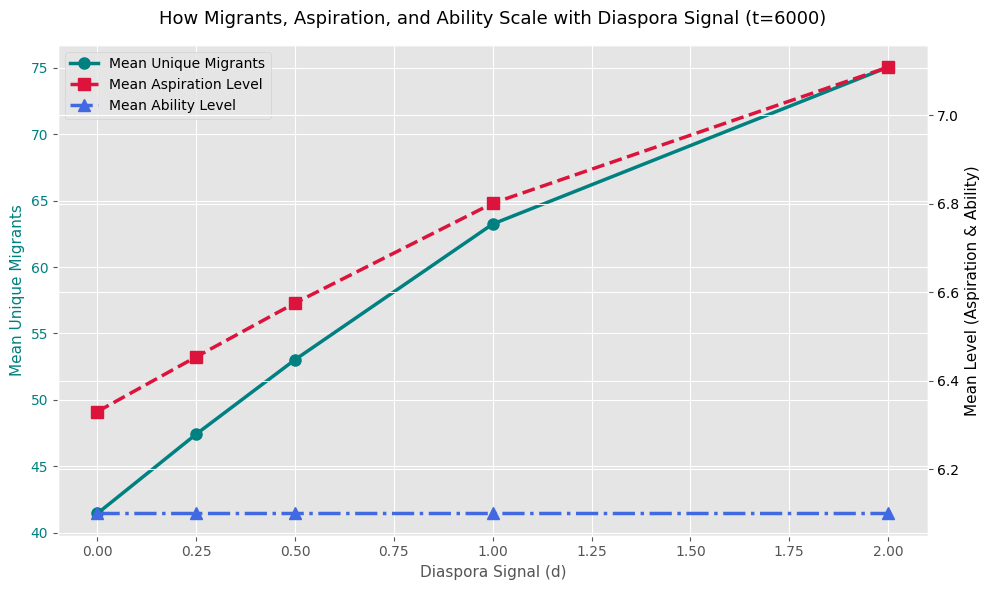

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load dataset
df_analysis = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_analysis.columns = [c.strip() for c in df_analysis.columns]

# 2. Filter for final tick (t=6000) and baseline network (network-strength = 0.0) to isolate diaspora pull
final_df = df_analysis[(df_analysis['ticks'] == 6000) & (df_analysis['network-strength'] == 0.0)]

# 3. Group by diaspora-signal and calculate the means of migrants, aspiration, and ability
summary_stats = final_df.groupby('diaspora-signal')[[
    'unique-migrants',
    'mean-aspiration-level',
    'mean-ability-level',
    'share-high-ability'
]].mean().reset_index()

print("Summary Metrics at t=6000 (n=0.0):")
display(summary_stats.round(3))

# 4. Plotting the relationships
fig, ax1 = plt.subplots(figsize=(10, 6))
plt.style.use('ggplot')

# Left axis for Migrants and Aspiration (which share a similar numeric scale)
color1 = 'teal'
ax1.set_xlabel('Diaspora Signal (d)', fontsize=11)
ax1.set_ylabel('Mean Unique Migrants', color=color1, fontsize=11)
line1 = ax1.plot(summary_stats['diaspora-signal'], summary_stats['unique-migrants'],
                 marker='o', markersize=8, color=color1, linewidth=2.5, label='Mean Unique Migrants')
ax1.tick_params(axis='y', labelcolor=color1)

# Create twin axis for mean aspiration level and mean ability level
ax2 = ax1.twinx()
color2 = 'crimson'
color3 = 'royalblue'
ax2.set_ylabel('Mean Level (Aspiration & Ability)', color='black', fontsize=11)

line2 = ax2.plot(summary_stats['diaspora-signal'], summary_stats['mean-aspiration-level'],
                 marker='s', markersize=8, color=color2, linestyle='--', linewidth=2.5, label='Mean Aspiration Level')
line3 = ax2.plot(summary_stats['diaspora-signal'], summary_stats['mean-ability-level'],
                 marker='^', markersize=8, color=color3, linestyle='-.', linewidth=2.5, label='Mean Ability Level')
ax2.tick_params(axis='y', labelcolor='black')

# Combine legends
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('How Migrants, Aspiration, and Ability Scale with Diaspora Signal (t=6000)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

In [73]:
import pandas as pd

# Load dataset
df_phases = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_phases.columns = [c.strip() for c in df_phases.columns]

# Define checkpoints representing the end of each of our 3 identified phases
phase_times = {
    'Phase 1: Initial Growth (t=1200)': 1200,
    'Phase 2: Transition/Deceleration (t=2400)': 2400,
    'Phase 3: Saturation/Plateau (t=6000)': 6000
}

records = []
# Let's calculate the overall mean metrics at these key transition checkpoints
for phase_name, t in phase_times.items():
    t_df = df_phases[df_phases['ticks'] == t]
    mean_unique = t_df['unique-migrants'].mean()
    mean_cumulative = t_df['cumulative-migrations'].mean()
    records.append({
        'Phase / Timeline checkpoint': phase_name,
        'Mean Unique Migrants': round(mean_unique, 2),
        'Mean Cumulative Migrations': round(mean_cumulative, 2)
    })

df_summary = pd.DataFrame(records)
display(df_summary)

,Phase / Timeline checkpoint,Mean Unique Migrants,Mean Cumulative Migrations
0,Phase 1: Initial Growth (t=1200),31.54,45.53
1,Phase 2: Transition/Deceleration (t=2400),46.51,76.24
2,Phase 3: Saturation/Plateau (t=6000),56.86,127.89


In [3]:
import pandas as pd
import os

# Adjust file path if necessary (checking common Google Colab paths)
file_path = 'Diaspora_sweep_v2.csv'
if not os.path.exists(file_path) and os.path.exists('/content/Diaspora_sweep_v2.csv'):
    file_path = '/content/Diaspora_sweep_v2.csv'

# Load dataset
df_phases = pd.read_csv(file_path, skiprows=6)
df_phases.columns = [c.strip() for c in df_phases.columns]

# Filter for active social influence (diaspora-signal > 0 and network-strength > 0)
active_social_df = df_phases[(df_phases['diaspora-signal'] > 0) & (df_phases['network-strength'] > 0)]

# Define the three phase checkpoints
phase_times = {
    'Phase 1: Initial Growth (t=1200)': 1200,
    'Phase 2: Transition/Deceleration (t=2400)': 2400,
    'Phase 3: Saturation/Plateau (t=6000)': 6000
}

records = []
for phase_name, t in phase_times.items():
    t_df = active_social_df[active_social_df['ticks'] == t]
    mean_unique = t_df['unique-migrants'].mean()
    mean_cumulative = t_df['cumulative-migrations'].mean()
    records.append({
        'Phase / Timeline checkpoint': phase_name,
        'Mean Unique Migrants': round(mean_unique, 2),
        'Mean Cumulative Migrations': round(mean_cumulative, 2)
    })

df_summary_active = pd.DataFrame(records)
display(df_summary_active)

,Phase / Timeline checkpoint,Mean Unique Migrants,Mean Cumulative Migrations
0,Phase 1: Initial Growth (t=1200),32.73,46.80
1,Phase 2: Transition/Deceleration (t=2400),49.06,78.86
2,Phase 3: Saturation/Plateau (t=6000),61.30,132.40


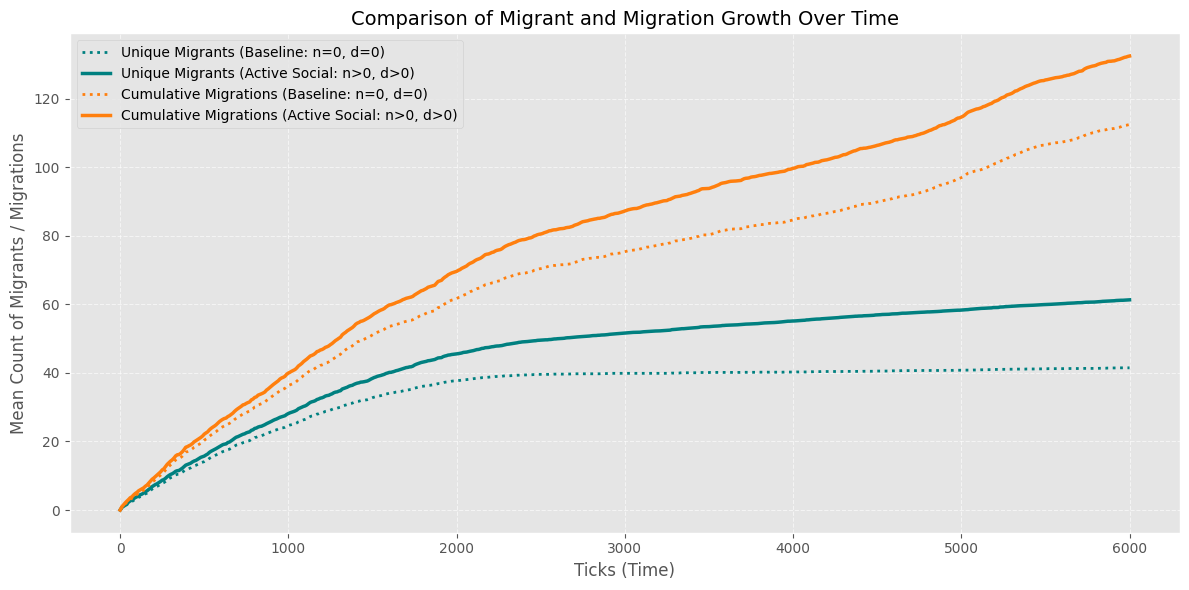

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load dataset
df_compare = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_compare.columns = [c.strip() for c in df_compare.columns]

# 2. Define groups
baseline_runs = df_compare[(df_compare['network-strength'] == 0.0) & (df_compare['diaspora-signal'] == 0.0)]
active_social_runs = df_compare[(df_compare['network-strength'] > 0.0) & (df_compare['diaspora-signal'] > 0.0)]

# 3. Calculate mean progression over time (ticks)
baseline_time = baseline_runs.groupby('ticks')[['unique-migrants', 'cumulative-migrations']].mean().reset_index()
active_time = active_social_runs.groupby('ticks')[['unique-migrants', 'cumulative-migrations']].mean().reset_index()

# 4. Plot Comparison
plt.figure(figsize=(12, 6))
plt.style.use('ggplot')

# Plot Unique Migrants
plt.plot(baseline_time['ticks'], baseline_time['unique-migrants'],
         label='Unique Migrants (Baseline: n=0, d=0)', color='teal', linestyle=':', linewidth=2)
plt.plot(active_time['ticks'], active_time['unique-migrants'],
         label='Unique Migrants (Active Social: n>0, d>0)', color='teal', linestyle='-', linewidth=2.5)

# Plot Cumulative Migrations
plt.plot(baseline_time['ticks'], baseline_time['cumulative-migrations'],
         label='Cumulative Migrations (Baseline: n=0, d=0)', color='tab:orange', linestyle=':', linewidth=2)
plt.plot(active_time['ticks'], active_time['cumulative-migrations'],
         label='Cumulative Migrations (Active Social: n>0, d>0)', color='tab:orange', linestyle='-', linewidth=2.5)

plt.title('Comparison of Migrant and Migration Growth Over Time', fontsize=14)
plt.xlabel('Ticks (Time)', fontsize=12)
plt.ylabel('Mean Count of Migrants / Migrations', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

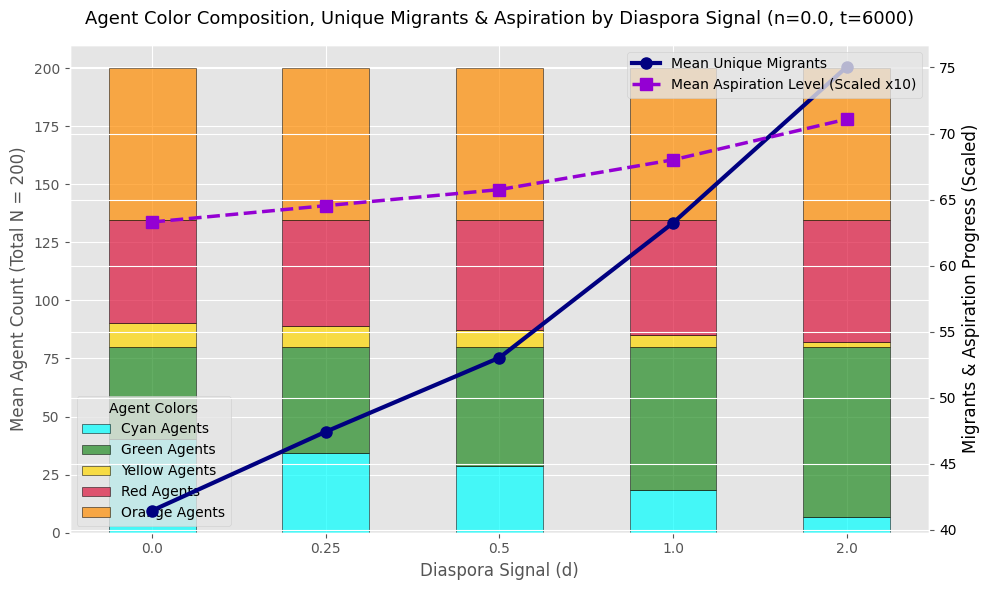

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the dataset
df_colors = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_colors.columns = [c.strip() for c in df_colors.columns]

# 2. Filter for baseline network (n=0.0) at the final timestep (t=6000) to isolate diaspora pull
final_baseline = df_colors[(df_colors['network-strength'] == 0.0) & (df_colors['ticks'] == 6000)]

# Identify color count columns and clean their labels
color_cols = [c for c in final_baseline.columns if 'color' in c]
clean_names = [c.split('=')[-1].replace(']', '').strip() for c in color_cols]

# 3. Group by diaspora-signal and compute means
grouped = final_baseline.groupby('diaspora-signal')[['unique-migrants', 'mean-aspiration-level'] + color_cols].mean().reset_index()
grouped.rename(columns=dict(zip(color_cols, clean_names)), inplace=True)

# 4. Plotting
fig, ax1 = plt.subplots(figsize=(10, 6))
plt.style.use('ggplot')

# Stacked area/bar chart for agent color composition
x = grouped['diaspora-signal'].astype(str)
bottoms = np.zeros(len(grouped))
color_palette = {
    'cyan': 'cyan',
    'green': 'forestgreen',
    'yellow': 'gold',
    'red': 'crimson',
    'orange': 'darkorange'
}

for col in ['cyan', 'green', 'yellow', 'red', 'orange']:
    if col in grouped.columns:
        ax1.bar(x, grouped[col], bottom=bottoms, label=f'{col.capitalize()} Agents',
                color=color_palette.get(col, 'grey'), alpha=0.7, edgecolor='black', width=0.5)
        bottoms += grouped[col].values

ax1.set_xlabel('Diaspora Signal (d)', fontsize=12)
ax1.set_ylabel('Mean Agent Count (Total N = 200)', fontsize=12)
ax1.tick_params(axis='y')
ax1.legend(loc='lower left', title='Agent Colors')

# Twin axis to overlay unique-migrants and aspiration lines
ax2 = ax1.twinx()
line1 = ax2.plot(x, grouped['unique-migrants'], color='navy', marker='o', linewidth=3,
                 markersize=8, label='Mean Unique Migrants')

# Plot Mean Aspiration Level on twin axis (using right axis scale)
line2 = ax2.plot(x, grouped['mean-aspiration-level'] * 10, color='darkviolet', marker='s', linewidth=2.5,
                 linestyle='--', markersize=8, label='Mean Aspiration Level (Scaled x10)')

ax2.set_ylabel('Migrants & Aspiration Progress (Scaled)', color='black', fontsize=12)
ax2.tick_params(axis='y', labelcolor='black')

# Combine legends for twin axis
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc='upper right')

plt.title('Agent Color Composition, Unique Migrants & Aspiration by Diaspora Signal (n=0.0, t=6000)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

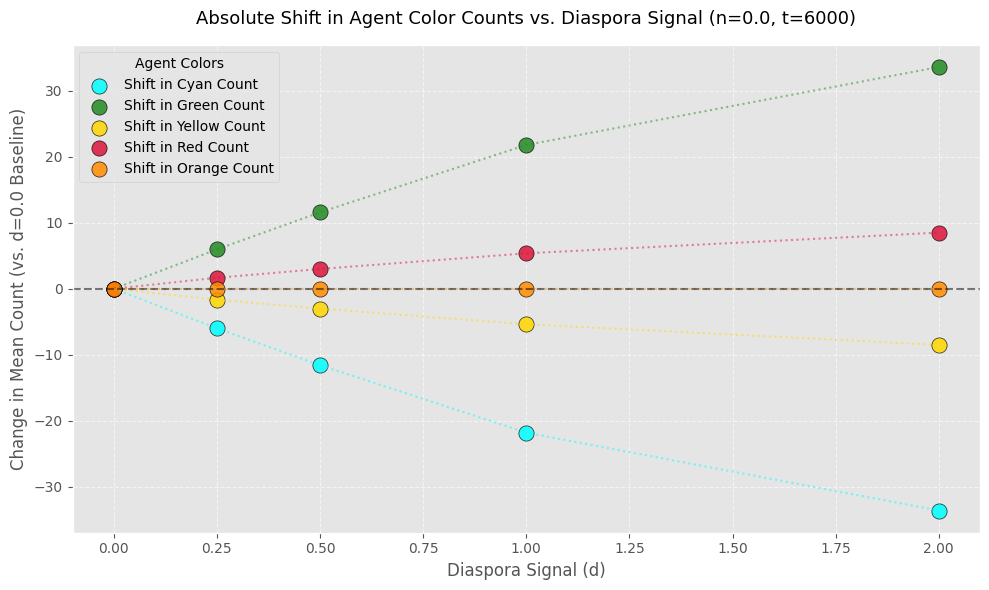

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df_scatter = pd.read_csv('Diaspora_sweep_v2.csv', skiprows=6)
df_scatter.columns = [c.strip() for c in df_scatter.columns]

# 2. Filter for final tick (t=6000) and baseline network (n=0.0)
final_baseline = df_scatter[(df_scatter['network-strength'] == 0.0) & (df_scatter['ticks'] == 6000)]

# Identify color count columns and clean their labels
color_cols = [c for c in final_baseline.columns if 'color' in c]
clean_names = [c.split('=')[-1].replace(']', '').strip() for c in color_cols]

# 3. Group by diaspora-signal and compute means
grouped_scatter = final_baseline.groupby('diaspora-signal')[color_cols].mean()
grouped_scatter.columns = clean_names

# 4. Calculate change relative to d=0.0 baseline
baseline_vals = grouped_scatter.loc[0.0]
color_shifts = grouped_scatter.sub(baseline_vals).reset_index()

# 5. Plotting as a scatter plot
plt.figure(figsize=(10, 6))
plt.style.use('ggplot')

colors_to_plot = ['cyan', 'green', 'yellow', 'red', 'orange']
color_palette = {
    'cyan': 'cyan',
    'green': 'forestgreen',
    'yellow': 'gold',
    'red': 'crimson',
    'orange': 'darkorange'
}

for col in colors_to_plot:
    if col in color_shifts.columns:
        plt.scatter(
            color_shifts['diaspora-signal'],
            color_shifts[col],
            color=color_palette.get(col, 'grey'),
            s=120,
            edgecolors='black',
            alpha=0.85,
            label=f'Shift in {col.capitalize()} Count'
        )
        # Add a dashed trendline for visual guide
        plt.plot(
            color_shifts['diaspora-signal'],
            color_shifts[col],
            color=color_palette.get(col, 'grey'),
            linestyle=':',
            alpha=0.5
        )

plt.title('Absolute Shift in Agent Color Counts vs. Diaspora Signal (n=0.0, t=6000)', fontsize=13, pad=15)
plt.xlabel('Diaspora Signal (d)', fontsize=12)
plt.ylabel('Change in Mean Count (vs. d=0.0 Baseline)', fontsize=12)
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.legend(loc='best', title='Agent Colors')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Summary of Agent Color Shifts (vs. $d=0.0$ Baseline at $t=6000$, $n=0.0$)

The table below shows the percentage change in the mean count of agents belonging to each aspiration category (represented by colors) as the diaspora signal ($d$) intensifies.

* **Low-aspiration groups** (**Cyan** and **Yellow**) experience systematic, step-wise reductions.
* **High-aspiration groups** (**Green** and **Red**) show corresponding systematically rising representation.
* **Maximum-aspiration group** (**Orange**) remains completely unchanged, serving as a fixed ceiling control group.

| Diaspora Signal ($d$) | Cyan (%) | Green (%) | Yellow (%) | Red (%) | Orange (%) |
|---|---|---|---|---|---|
| **0.25** | -14.84% | +15.03% | -15.77% | +3.79% | 0.00% |
| **0.50** | -28.77% | +29.14% | -28.39% | +6.83% | 0.00% |
| **1.00** | -54.15% | +54.83% | -50.79% | +12.22% | 0.00% |
| **2.00** | -83.50% | +84.55% | -80.44% | +19.35% | 0.00% |